# preparation

## Packages

In [24]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import multiprocessing as mp
from matplotlib import gridspec
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.preprocessing import MinMaxScaler
from sklearn.mixture import GaussianMixture
from sklearn import metrics
from tqdm import tqdm

warnings.filterwarnings("ignore")
%matplotlib inline

## Constants

In [25]:
plt.rcParams['figure.dpi'] = 300
# https://www.encodeproject.org/data-standards/wgbs/
names = ['chrom', 'start', 'end', 'name', '?', 'strand', 'thickStart', 'thickEnd',
         'itemRgb', 'coverage', 'score']
chroms = ['L1', 'L2', 'L3', 'L4', 'L5']
pos = [305, 315, 325, 335, 345, 355, 365, 375, 385, 395, 405, 415, 425, 435,
       445, 455, 465, 475, 485, 495, 505, 515, 525, 535, 545, 555, 565, 575,
       585, 595, 605, 615, 625, 635, 645, 655, 665, 675, 685, 695, 705, 715,
       725, 735, 745, 755, 765, 775, 785, 795, 805, 815, 825, 835, 845, 855,
       865, 875, 885, 895, 905, 915, 925, 935, 945, 955, 965, 975, 985, 995]
pos = [p - 1 for p in pos]
seed = 42

## Functions

In [26]:
def show_read_count(_cnt, sort=False, title=''):
    length = len(_cnt)
    if sort:
        _cnt = dict(sorted(_cnt.items(), key=lambda x: x[1]))
    x = [str(i) for i in _cnt.keys()]
    y = list(_cnt.values())
    mean = np.mean(y)
    bottom = [i if i < mean else mean for i in y]
    median = [0 if i > mean else mean - i for i in y]
    top = [i - mean if i > mean else 0 for i in y]

    fig = plt.figure(constrained_layout=True, figsize=[14, 6])
    spec = gridspec.GridSpec(ncols=2, nrows=1, width_ratios=[6, 1], figure=fig)

    ax = fig.add_subplot(spec[0])
    ax.bar(x, bottom)
    ax.bar(x, median, bottom=bottom, color='grey', alpha=.1)
    ax.bar(x, top, bottom=mean)
    ax.hlines(mean, xmin=-0.5, xmax=length-0.5, colors='r', linestyles='dashed')
    ax.set_xlim(-0.5, length-0.5)
    ax.set_xticklabels(x, rotation=90)
    # ax.set_ylim(0, 1.05)
    ax.set_ylabel('Accuracy')
    ax.set_xlabel('Barcode')

    ax = fig.add_subplot(spec[1])

    sns.histplot(y=y, ax=ax, kde=True, bins=10)
    ax.set_ylabel('Barcode\'s accuracy')
    ax.set_ylim(0, 1.05)
    fig.suptitle(title)
    plt.show()


def show_TSNE(df_tsne, title=None, path=None):
    fig, ax = plt.subplots()
    unique = np.unique(df_tsne['label'])
    for i in range(len(unique)):
        tmp = df_tsne[df_tsne.label == i]
        ax.scatter(tmp.x, tmp.y, s=2.5, label=i)
    plt.title(title)
    plt.axis('off')
    plt.legend(ncol=5, fontsize='xx-small', bbox_to_anchor=(1, 0))
    if path is not None:
        plt.savefig(os.path.join(path, '%s' % title.split(',')[0]))
        plt.close()


def showMethylation(df, length, title=None):
    fontsize = 18
    x = np.arange(length)
    y = np.zeros(length)
    for index, row in df.iterrows():
        y[row['start']] += row['score']
    fig, ax = plt.subplots(figsize=[14, 4])
    fig.suptitle(title, fontsize=20)

    ax.bar(x, y, width=3)
    # ax.hlines(34.5, 0, length, linestyle='dashed', colors='# c82423', alpha=.7, linewidth=2.5)
    ax.set_xlim(0, length)
    ax.set_ylim(0, 100)
    ax.set_xlabel('Template location', fontsize=fontsize)
    ax.set_ylabel('Methyl prob', fontsize=fontsize)
    ax.tick_params(labelsize=14)


def hamming(_a, _b):
    return sum(c1 != c2 for c1, c2 in zip(_a, _b))


def get_barcode(_b, _barcodes):
    _min_dis, _min_barcode = 99, ''
    for bar in _barcodes:
        if hamming(_b, bar) < _min_dis:
            _min_dis = hamming(_b, bar)
            _min_barcode = bar
    return _min_dis, _min_barcode


def anti_sparsity(_seq, _seed):
    _seq = np.array([int(i) for i in _seq])
    rdsta = np.random.RandomState(_seed)
    rdseq = np.array(rdsta.randint(2, size=len(_seq)))
    res = [(i + j) % 2 for i, j in zip(_seq, rdseq)]
    res = ''.join([str(i) for i in res])
    return res


def show_persite_accuracy(_x, _y, _error=None, ch=None):
    length = len(_x)
    _x = [str(_) for _ in _x]
    mean = np.mean(_y)
    bottom = [i if i < mean else mean for i in _y]
    median = [0 if i > mean else mean - i for i in _y]
    top = [i - mean if i > mean else 0 for i in _y]

    fig = plt.figure(constrained_layout=True, figsize=[14, 6])
    spec = gridspec.GridSpec(ncols=2, nrows=1, width_ratios=[6, 1], figure=fig)

    ax = fig.add_subplot(spec[0])
    ax.bar(_x, bottom)
    ax.bar(_x, median, bottom=bottom, color='grey', alpha=.1)
    ax.bar(_x, top, bottom=mean)
    ax.errorbar(_x, _y, _error, ecolor='black', linestyle='')
    ax.hlines(mean, xmin=-0.5, xmax=length-0.5, colors='r', linestyles='dashed')
    ax.set_xlim(-0.5, length-0.5)
    ax.set_ylim(0, 1)
    ax.set_title('%s: average accuracy rate = %.4f' % (ch, np.mean(_y)))
    ax.set_xticklabels(_x, rotation=90)

    ax = fig.add_subplot(spec[1])
    sns.histplot(y=_y, ax=ax, kde=True, bins=10)


def distributor(_dataframe, _barcodes, _path, _seed=42, show_tsne=False, _tsne_path=None):
    scaler = MinMaxScaler()
    dic = {barcode: df for barcode, df in _dataframe.groupby('min_barcode', sort=False)}
    dic = dict(sorted(dic.items(), key=lambda _: len(_[1]), reverse=True))
    barcodes = set(_barcodes.barcode)
    for barcode, df in dic.items():
        index = _barcodes[_barcodes.barcode == barcode].index[0]
        x = scaler.fit_transform(df[pos])

        best_kmeans, best_score, best_n = None, -1, -1
        for n in range(2, len(_barcodes) // 4):
            kmeans = KMeans(n_clusters=n, random_state=_seed)
            kmeans.fit(x)
            score = metrics.silhouette_score(x, kmeans.labels_)
            if score > best_score:
                best_kmeans, best_score, best_n = kmeans, score, n
            elif best_score - score > 0.1:
                break
        df['label'] = best_kmeans.labels_

        min_dis, min_label = 99, -1
        for label, d in df.groupby('label'):
            if d.min_dis.mean() < min_dis:
                min_dis, min_label = d.min_dis.mean(), label
        dropped_data = df[df.label != min_label]
        df[df.label == min_label].index.to_series().to_csv(
            _path + "%d.txt" % index, index=False, header=['read_id'])

        barcodes.remove(barcode)
        dropped_data[['min_dis', 'min_barcode']] = dropped_data.barcode.apply(
            lambda _: pd.Series(get_barcode(_, barcodes))
        )
        for b, d in dropped_data.groupby('min_barcode', sort=False):
            dic[b] = pd.concat([dic[b], d])
        barcodes.add(barcode)

        if show_tsne:
            tsne = TSNE(random_state=_seed)
            tsne.fit_transform(x)
            df_tsne = pd.DataFrame(tsne.embedding_, columns=['x', 'y'])
            df_tsne['label'] = best_kmeans.labels_
            show_TSNE(
                df_tsne,
                title='%d, reads: %d, n_cluster: %d, score: %.4f' % (index, len(x), best_n, best_score),
                path=_tsne_path
            )


def load_data(_path, _code, _barcode_pos, per_read_th=0.175):
    # todo: optimize per_read_th
    per_read = pd.read_csv(_path, sep='\t')
    per_read = per_read[per_read.pos.isin(pos)]
    per_read['mod_prob'] = per_read['mod_log_prob'].apply(np.exp)
    barcode_pos = pd.read_csv(_barcode_pos)

    dataframes = []
    for ch in chroms:
        per_read_ch = per_read[per_read.chrm == ch]
        methyl = {}
        for index, df in per_read_ch.groupby('read_id'):
            methyl[index] = {k: v for k, v in zip(df.pos, df.mod_prob)}
        df = pd.DataFrame(methyl).T
        df = df.dropna()
        df['chrom'] = ch
        dataframes.append(df)

    for i in range(len(dataframes)):
        dataframes[i]['barcode'] = ""
        for p in barcode_pos[barcode_pos.chrom == chroms[i]].pos:
            dataframes[i]['barcode'] += dataframes[i][p].apply(lambda x: '1' if x > per_read_th else '0')
        dataframes[i][['min_dis', 'min_barcode']] = dataframes[i].barcode.apply(
            lambda x: pd.Series(get_barcode(x, _code[_code.chrom == chroms[i]].barcode))
        )

    return dataframes

# Hu_1

In [29]:
res_dir = '../data/hu/hu_1_hamming_dropna'
hu_20_50 = pd.read_csv('../data/csv/hu_20+50.csv',
                       converters={'barcode': str, 'info': str, 'seed': int})
mod_scores = pd.DataFrame()
for i in os.listdir(res_dir):
    mod = pd.read_csv(os.path.join(res_dir, i, 'modified_bases.5mC.bed'),
                      sep='\t', names=names)
    mod = mod[mod.start.isin(pos)]
    mod['index'] = int(i)
    ch = hu_20_50.loc[int(i), 'chrom']
    mod.loc[mod.start.isin(pos[:50]), 'truth'] = list(hu_20_50.loc[int(i), 'info'])
    mod.loc[mod.start.isin(pos[50:]), 'truth'] = list(hu_20_50.loc[int(i), 'barcode'])
    mod = mod.dropna()
    mod_scores = pd.concat((mod_scores, mod))
mod_scores = mod_scores.sort_values(by=['index', 'start']).reset_index(drop=True)
mod_scores = mod_scores[mod_scores.start.isin(pos[:50])]
gmm = GaussianMixture(n_components=2, random_state=seed, covariance_type='spherical').fit(mod_scores.score.values.reshape(-1, 1))
th = gmm.means_.mean()
mod_scores['pred'] = mod_scores.score > th
mod_scores['pred'] = mod_scores['pred'].astype(int)
mod_scores['truth'] = mod_scores['truth'].astype(int)
mod_scores['th'] = th

# mod_scores.to_csv('/home/eason/codes/methyl/csv/4editions/0612_hu_1_naive.csv', index=False)

[]

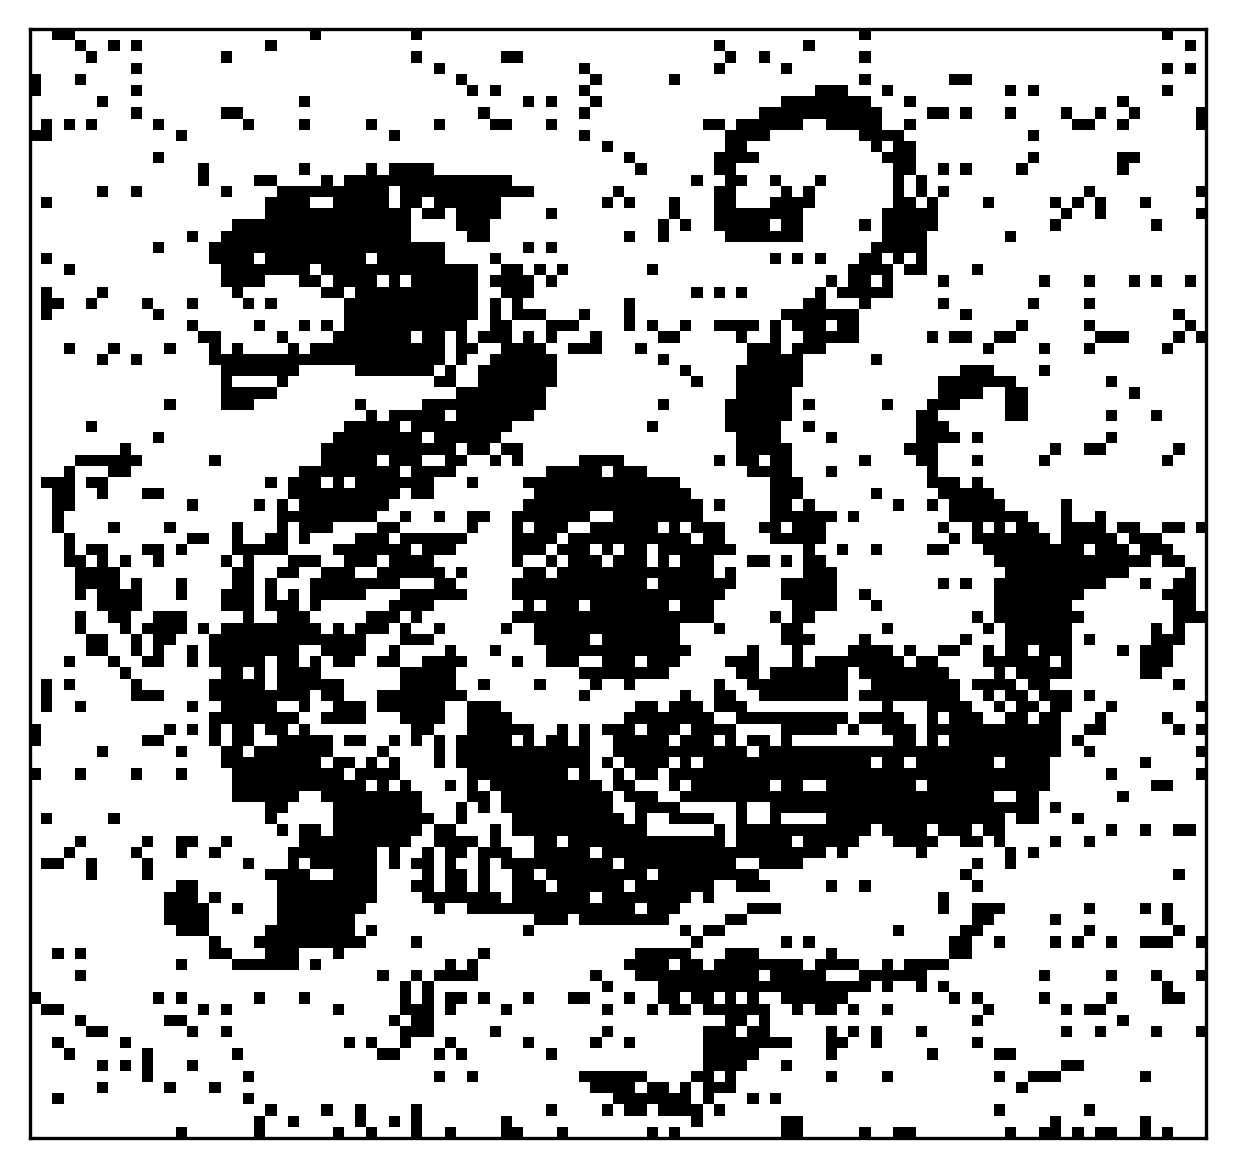

In [30]:
hu_20_50['pred'] = ''
for index, mod in mod_scores.groupby('index'):
    mod = mod.sort_values(by='start')
    hu_20_50.loc[index, 'pred'] = ''.join(mod.pred.values.astype(str))
hu_20_50 = hu_20_50[hu_20_50.seed != -1]
hu_20_50['pred'] = hu_20_50.apply(lambda x: anti_sparsity(x['pred'], x['seed']), axis=1)
img_binary = np.array([i for i in ''.join(hu_20_50['pred'].values)[:10395]], dtype=int).reshape(99, -1)
fig, ax = plt.subplots()
ax.imshow(img_binary, cmap='gist_gray')
ax.set_xticks([])
ax.set_yticks([])

# Hu_2

In [31]:
res_dir = '../data/hu/hu_1_hamming_distribute_iter'
hu_20_50 = pd.read_csv('../data/csv/hu_20+50.csv',
                       converters={'barcode': str, 'info': str, 'seed': int})
mod_scores = pd.DataFrame()
for i in os.listdir(res_dir):
    mod = pd.read_csv(os.path.join(res_dir, i, 'modified_bases.5mC.bed'),
                      sep='\t', names=names)
    mod = mod[mod.start.isin(pos)]
    mod['index'] = int(i)
    ch = hu_20_50.loc[int(i), 'chrom']
    mod.loc[mod.start.isin(pos[:50]), 'truth'] = list(hu_20_50.loc[int(i), 'info'])
    mod.loc[mod.start.isin(pos[50:]), 'truth'] = list(hu_20_50.loc[int(i), 'barcode'])
    mod = mod.dropna()
    mod_scores = pd.concat((mod_scores, mod))
mod_scores = mod_scores.sort_values(by=['index', 'start']).reset_index(drop=True)
mod_scores = mod_scores[mod_scores.start.isin(pos[:50])]
gmm = GaussianMixture(n_components=2, random_state=seed, covariance_type='spherical').fit(mod_scores.score.values.reshape(-1, 1))
th = gmm.means_.mean()
mod_scores['pred'] = mod_scores.score > th
mod_scores['pred'] = mod_scores['pred'].astype(int)
mod_scores['truth'] = mod_scores['truth'].astype(int)
mod_scores['th'] = th

# mod_scores.to_csv('/home/eason/codes/methyl/csv/4editions/0612_hu_1_dynamic.csv', index=False)

[]

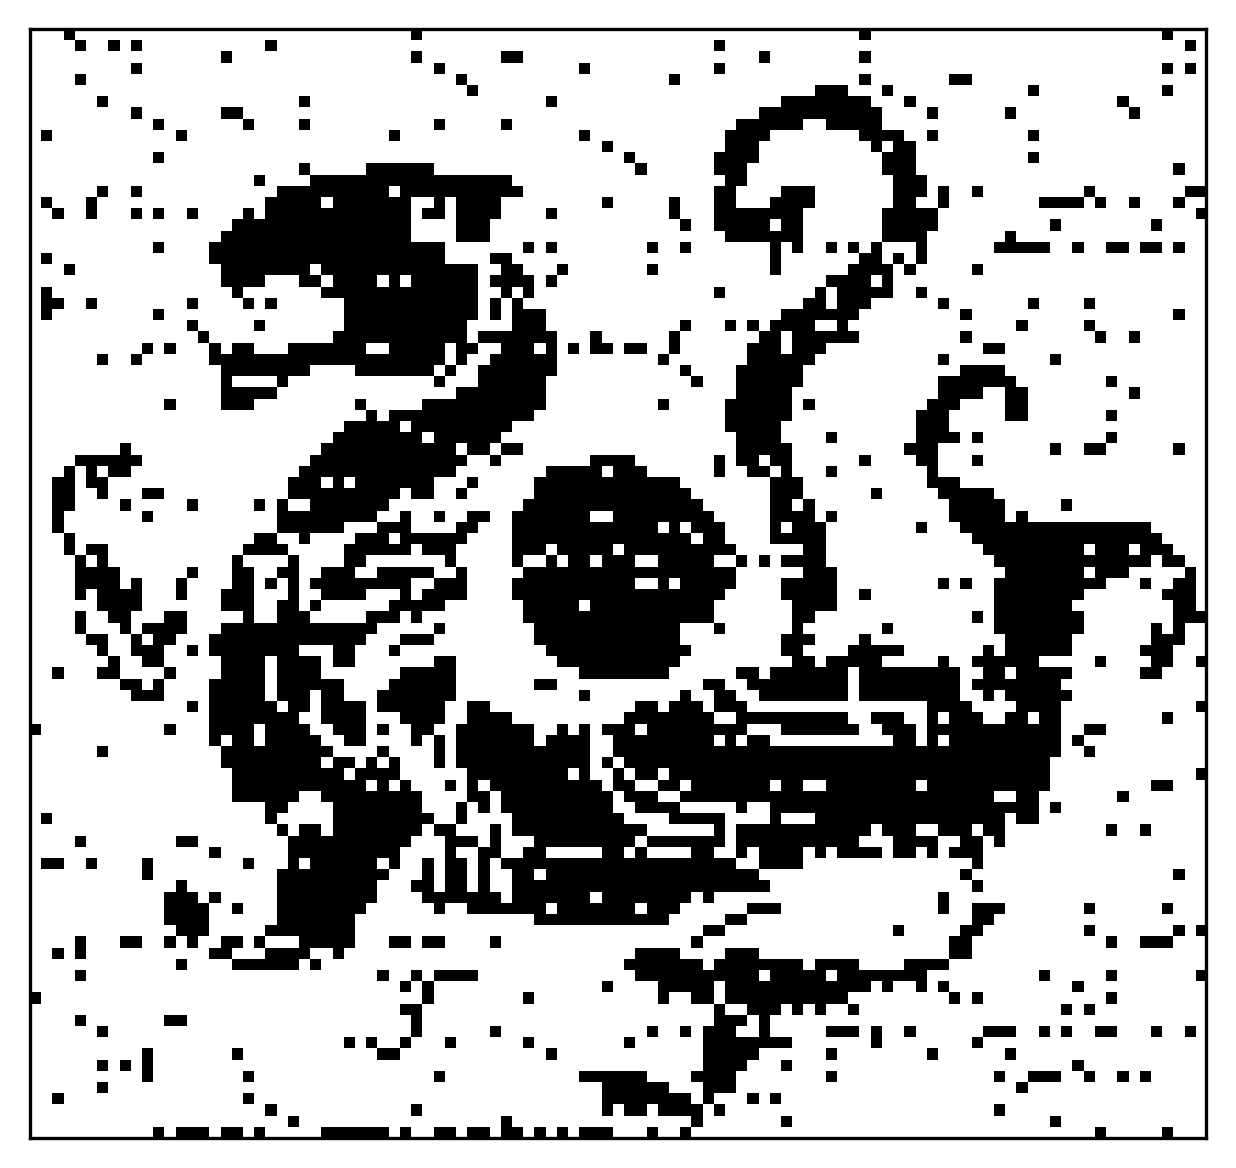

In [32]:
hu_20_50['pred'] = ''
for index, mod in mod_scores.groupby('index'):
    mod = mod.sort_values(by='start')
    hu_20_50.loc[index, 'pred'] = ''.join(mod.pred.values.astype(str))
hu_20_50 = hu_20_50[hu_20_50.seed != -1]
hu_20_50['pred'] = hu_20_50.apply(lambda x: anti_sparsity(x['pred'], x['seed']), axis=1)
img_binary = np.array([i for i in ''.join(hu_20_50['pred'].values)[:10395]], dtype=int).reshape(99, -1)
fig, ax = plt.subplots()
ax.imshow(img_binary, cmap='gist_gray')
ax.set_xticks([])
ax.set_yticks([])

# Hu3

In [50]:
res_dir = '../data/hu/hu_2_hamming_distribute_iter_1'
barcode_pos = pd.read_csv('../data/csv/best.csv')
info_pos = pd.read_csv('../data/csv/info_pos.csv')
hu_code = pd.read_csv('../data/csv/code_hu_0619.csv', converters={'barcode': str, 'info': str})

mod_scores = pd.DataFrame()
for i in os.listdir(res_dir):
    mod = pd.read_csv(os.path.join(res_dir, i, 'modified_bases.5mC.bed'),
                      sep='\t', names=names)
    mod = mod[mod.start.isin(pos)]
    ch = hu_code.loc[int(i), 'chrom']
    mod.loc[mod.start.isin(info_pos[info_pos.chrom == ch].pos), 'truth'] = list(hu_code.loc[int(i), 'info'])
    # mod.loc[mod.start.isin(barcode_pos[barcode_pos.chrom == ch].pos), 'truth'] = list(hu_code.loc[int(i), 'barcode'])
    mod['index'] = int(i)
    mod_scores = pd.concat((mod_scores, mod))
mod_scores = mod_scores.sort_values(by=['index', 'start']).reset_index(drop=True)
mod_scores = mod_scores.dropna()
gmm = GaussianMixture(n_components=2, random_state=seed, covariance_type='spherical').fit(mod_scores.score.values.reshape(-1, 1))
th = gmm.means_.mean()
mod_scores['pred'] = mod_scores.score > th
mod_scores['pred'] = mod_scores['pred'].astype(int)
mod_scores['truth'] = mod_scores['truth'].astype(int)
mod_scores['th'] = th

# mod_scores.to_csv('/home/eason/codes/methyl/csv/4editions/0622_hu_2_dynamic.csv', index=False)

[]

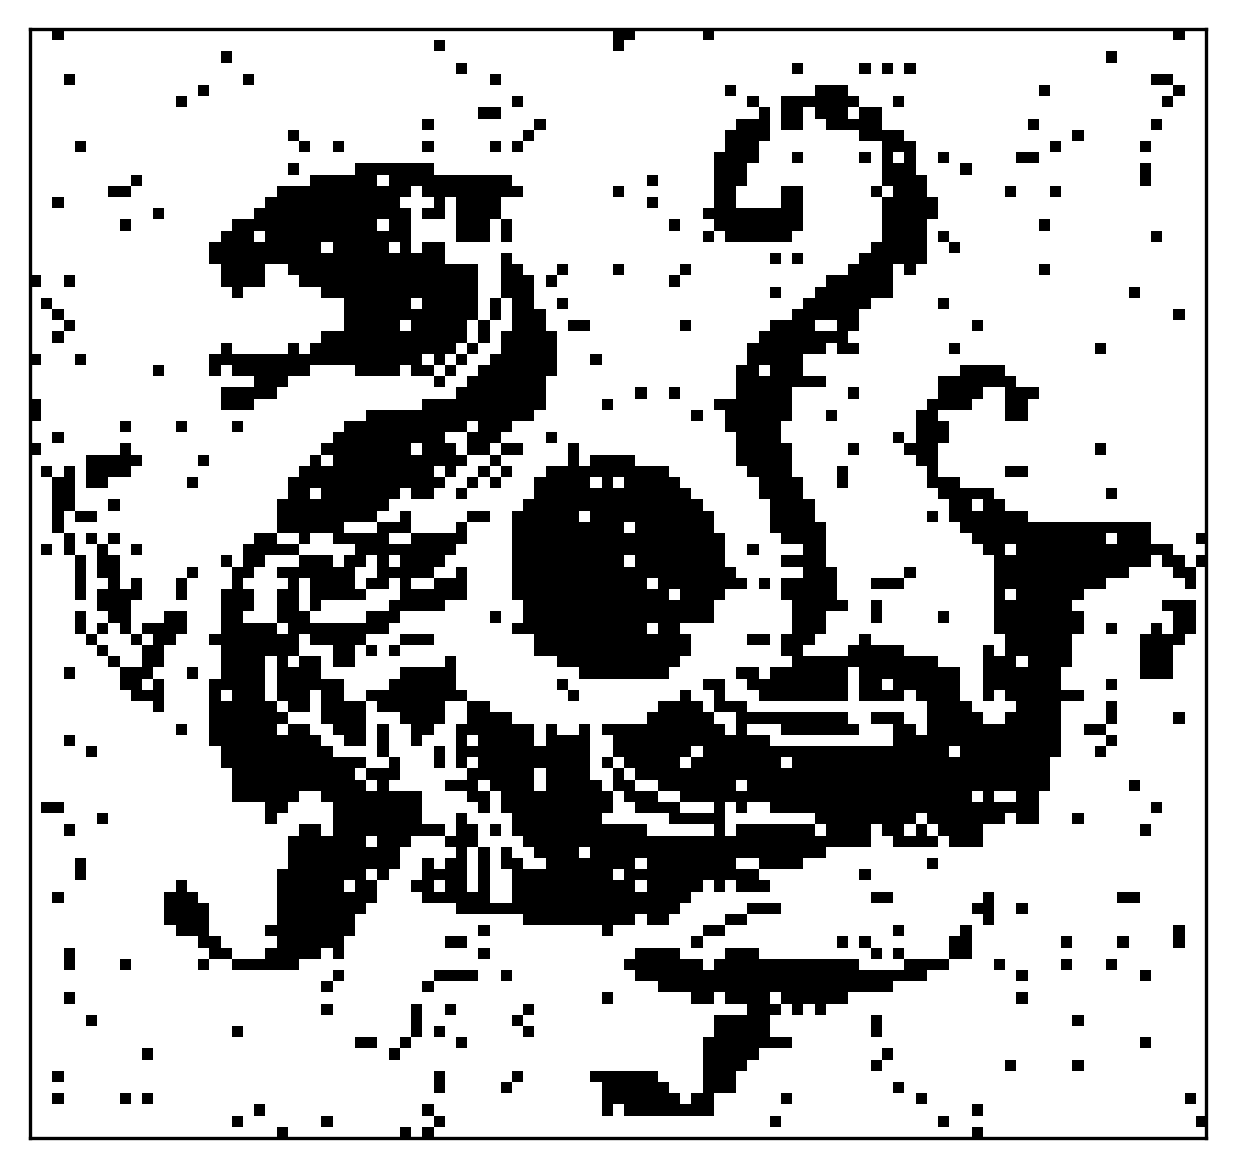

In [54]:
info_hu = pd.read_csv('../data/csv/info_hu_0619.csv')
infos = np.array([i for i in ''.join(mod_scores.pred.values.astype(str))[:10400]]).astype(str).reshape(208, -1)
infos = [''.join(i) for i in infos]
info_hu['pred'] = infos
info_hu['pred'] = info_hu.apply(lambda x: anti_sparsity(x['pred'], x['seed']), axis=1)
img_binary = np.array([i for i in ''.join(info_hu['pred'])[:10395]], dtype=int).reshape(99, -1)
fig, ax = plt.subplots()
ax.imshow(img_binary, cmap='gist_gray')
ax.set_xticks([])
ax.set_yticks([])

# 比较

Naive algorithm 0.9014084507042254
Dynamic clustering 0.9365258215962442
Site optimization 0.9632811828359554


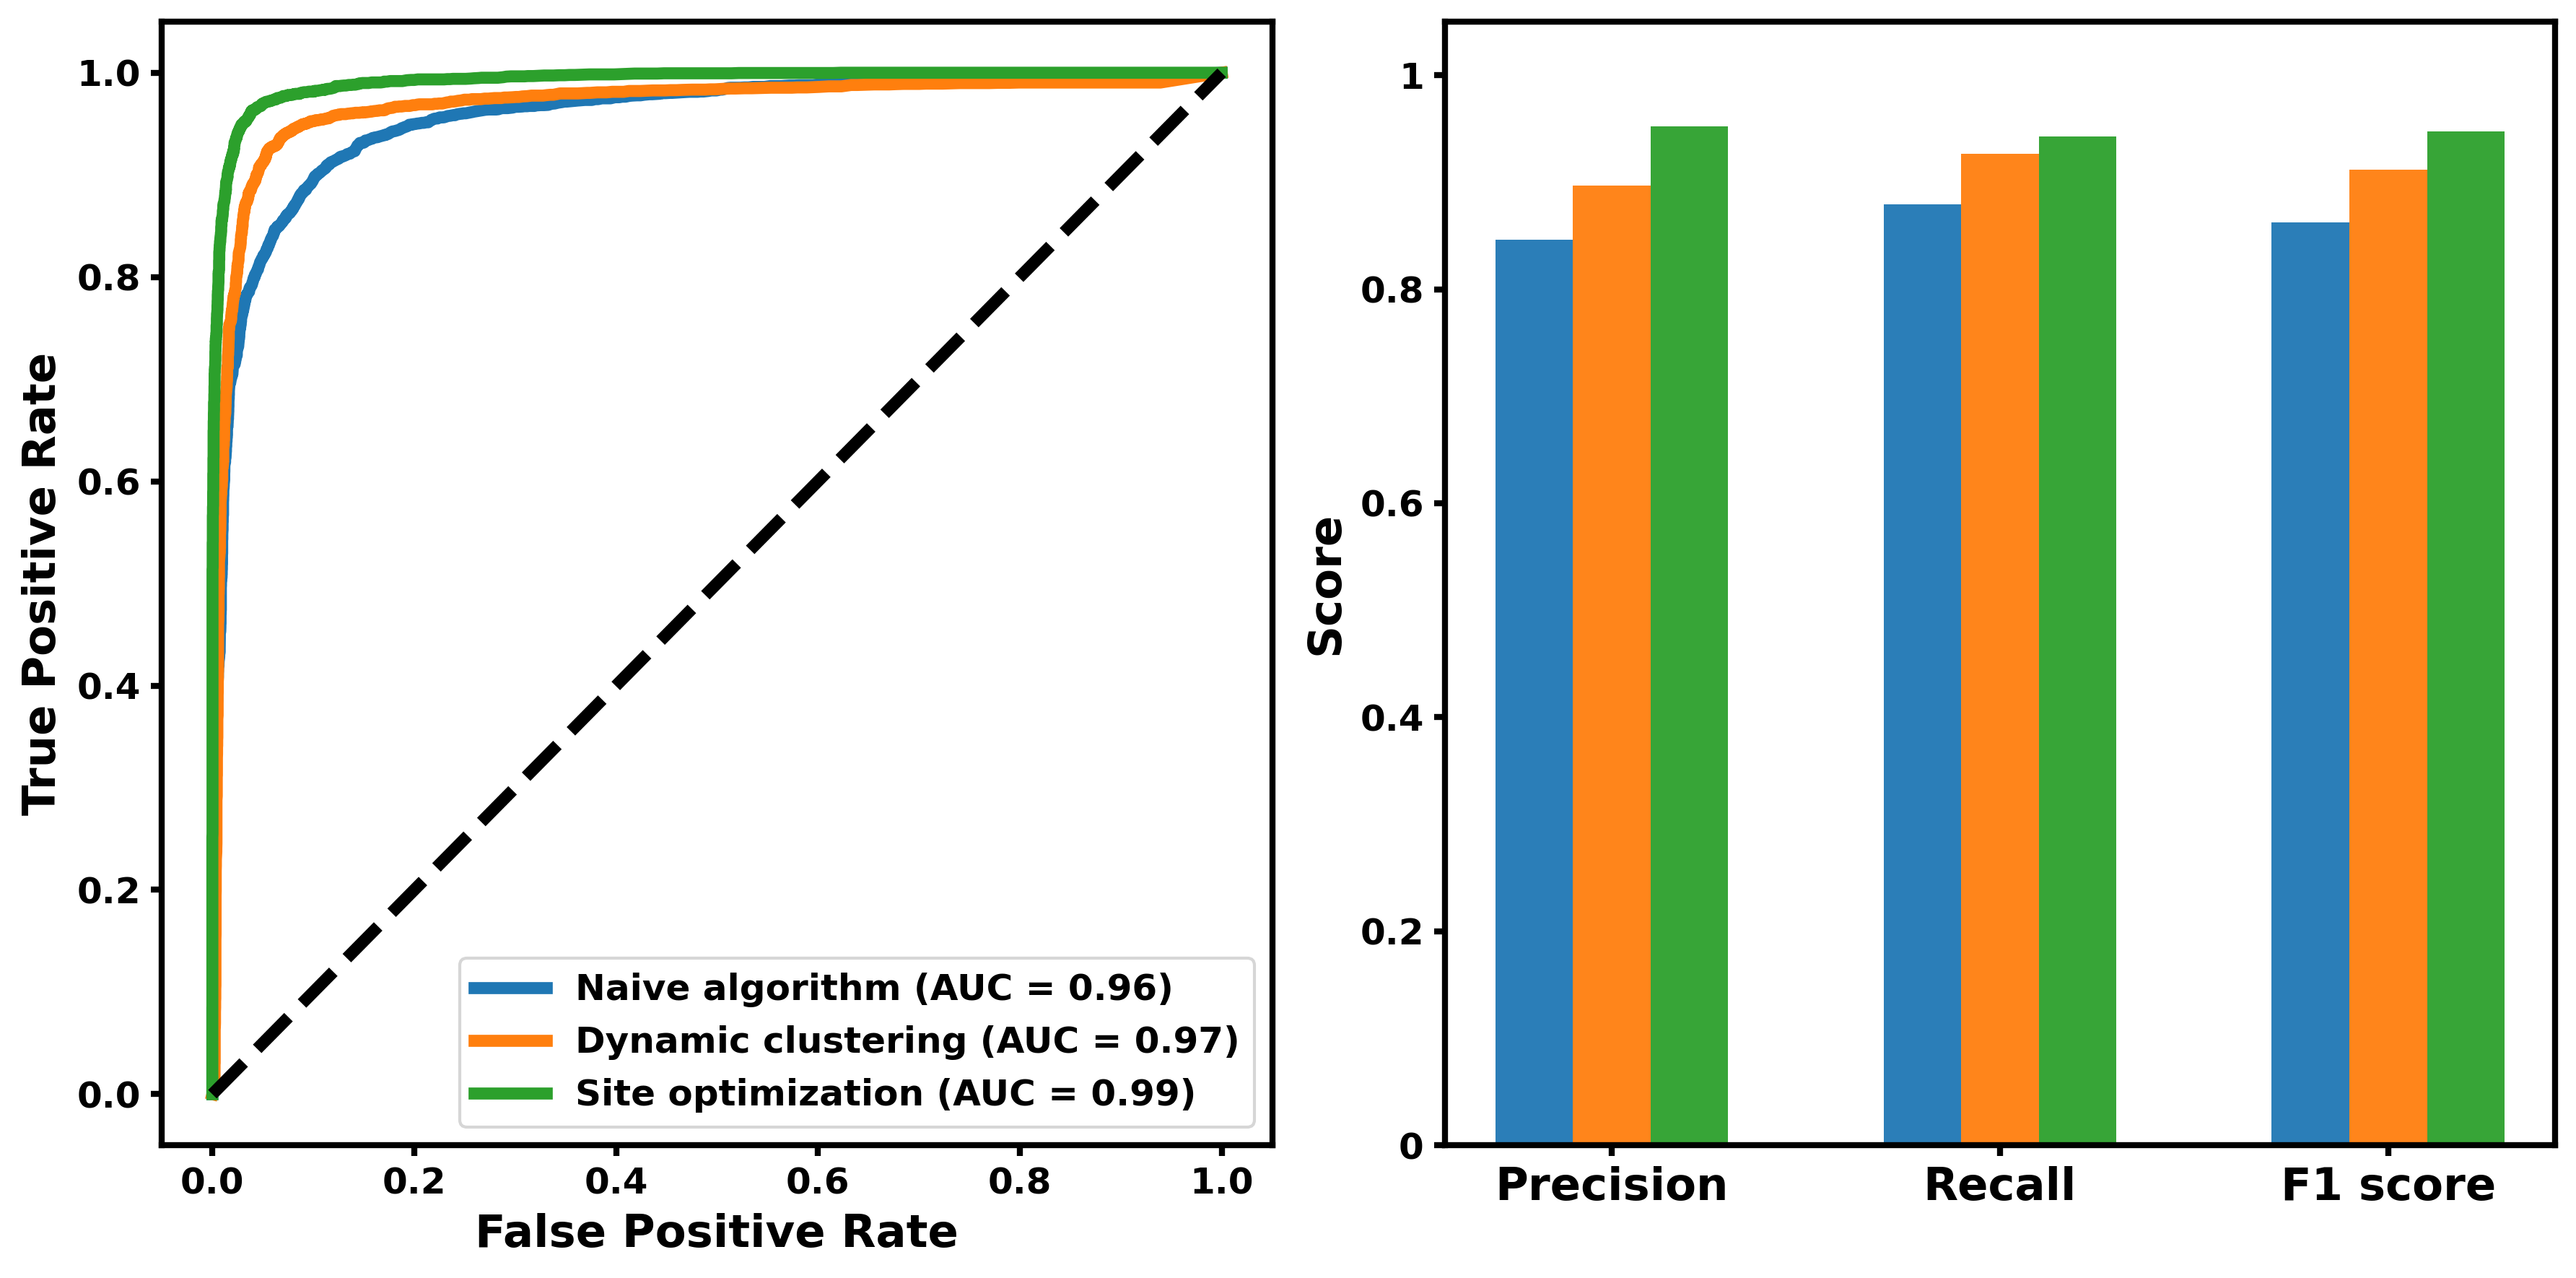

In [56]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import roc_curve, auc, accuracy_score, precision_recall_curve, precision_recall_fscore_support
from matplotlib.gridspec import GridSpec
from sklearn.preprocessing import MinMaxScaler


def set_ax(_ax):
    _ax.spines['bottom'].set_linewidth(2)
    _ax.spines['left'].set_linewidth(2)
    _ax.spines['top'].set_linewidth(2)
    _ax.spines['right'].set_linewidth(2)
    _ax.tick_params(labelsize=15, width=2)


def set_blank_ax(_ax):
    _ax.spines['bottom'].set_visible(False)
    _ax.spines['left'].set_visible(False)
    _ax.spines['top'].set_visible(False)
    _ax.spines['right'].set_visible(False)
    _ax.set_xticks([])
    _ax.set_yticks([])


def plot_roc(_mod_scores, _ax=None):
    if _ax is None:
        fig, _ax = plt.subplots(figsize=(6, 6))
    line_width = 4
    for name, df in _mod_scores.items():
        fpr, tpr, thresholds = roc_curve(df['truth'], df['score'])
        roc_auc = auc(fpr, tpr)
        _ax.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})', lw=line_width)
    set_ax(_ax)
    _ax.plot([0, 1], [0, 1], 'k--', lw=line_width)
    _ax.set_xlim([-0.05, 1.05])
    _ax.set_ylim([-0.05, 1.05])
    _ax.set_xticklabels(['%.1f' % i for i in _ax.get_xticks()], size=12, weight='bold')
    _ax.set_yticklabels(['%.1f' % i for i in _ax.get_yticks()], size=12, weight='bold')
    _ax.set_xlabel('False Positive Rate', size=15, weight='bold')
    _ax.set_ylabel('True Positive Rate', size=15, weight='bold')
    _ax.legend(loc='lower right', prop={'size': 12, 'weight': 'bold'})
    # _ax.set_title('Comparisons of the ROC curves of automatic samples (1), (2) and (3)', size=15, weight='bold')


def plot_pr(_mod_scores, _ax=None):
    if _ax is None:
        _, _ax = plt.subplots(figsize=(6, 6))
    # _ax.set_title('Comparisons of the ROC curves of automatic samples (1), (2) and (3)', size=15, weight='bold')
    for name, df in _mod_scores.items():
        precision, recall, thresholds = precision_recall_curve(df['truth'], df['score'])
        pr_auc = auc(recall, precision)
        _ax.plot(recall, precision, label=f'{name} (AUC = {pr_auc:.2f})', lw=4)
    set_ax(_ax)
    _ax.set_xlim([-0.05, 1.05])
    _ax.set_ylim([-0.05, 1.05])
    _ax.set_xlabel('Recall', size=15, weight='bold')
    _ax.set_ylabel('Precision', size=15, weight='bold')
    _ax.set_xticklabels(['%.1f' % i for i in _ax.get_xticks()], size=12, weight='bold')
    _ax.set_yticklabels(['%.1f' % i for i in _ax.get_yticks()], size=12, weight='bold')
    _ax.legend(loc='lower right', prop={'size': 12, 'weight': 'bold'})


def plot_acc(_accuracies, _names):
    colors = ['tab:blue', 'tab:orange', 'tab:green']
    fig = plt.figure(figsize=(8, 6), constrained_layout=True)
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 1])
    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1])
    fig.suptitle('Comparison of accuracy (3 editions of Hu)', size=15, weight='bold')
    for name, acc in _accuracies.items():
        ax1.boxplot(acc, positions=[list(_names.keys()).index(name)], widths=0.6,
                    patch_artist=True, medianprops=dict(color='black'),
                    boxprops=dict(facecolor=colors[list(_names.keys()).index(name)],
                                  color=colors[list(_names.keys()).index(name)]))
        sns.kdeplot(y=acc, label=name, ax=ax2, linewidth=4, fill=True)
    ax1.set_ylabel('Accuracy', size=15, weight='bold')
    ax1.set_ylim([0.4, 1.075])
    ax2.set_ylim([0.4, 1.075])
    ax1.set_xlabel("Tiger's edition", size=15, weight='bold')
    set_ax(ax1)
    set_ax(ax2)
    ax2.set_xlabel('Density', size=15, weight='bold')
    ax2.set_yticklabels([])
    ax2.legend(loc='lower right', prop={'size': 12, 'weight': 'bold'})
    plt.savefig('../figures/3_editions/3_editions_acc_box_dist.png', dpi=300, bbox_inches='tight', pad_inches=0.1)
    plt.show()


def plot_prf1(_mod_scores, _ax=None, _colors=None):
    if _ax is None:
        _, _ax = plt.subplots(figsize=(6, 6))
    if _colors is None:
        _colors = ['tab:blue', 'tab:orange', 'tab:green']
    # _ax.set_title('Comparison of PRF1 (3 editions of Tiger)', size=15, weight='bold')
    bar_width = 0.2
    for (name, df), c in zip(_mod_scores.items(), _colors):
        precision, recall, f1, _ = precision_recall_fscore_support(df['truth'], df['pred'], average='binary')
        _ax.bar(x=0.8 + list(_mod_scores.keys()).index(name) * bar_width,
               height=[precision], width=bar_width, color=c, label=f'{name}', alpha=0.95)
        _ax.bar(x=1.8 + list(_mod_scores.keys()).index(name) * bar_width,
                height=[recall], width=bar_width, color=c, alpha=0.95)
        _ax.bar(x=2.8 + list(_mod_scores.keys()).index(name) * bar_width,
                height=[f1], width=bar_width, color=c, alpha=0.95)
    set_ax(_ax)
    _ax.set_xticks([1, 2, 3])
    _ax.set_xticklabels(['Precision', 'Recall', 'F1 score'], size=15, weight='bold')
    _ax.set_ylim([0, 1.05])
    _ax.set_yticklabels([0, .2, .4, .6, .8, 1], size=12, weight='bold')
    _ax.set_ylabel('Score', size=15, weight='bold')


def main():
    res_dir = "../data/csv/4editions"
    names = {
        'Naive algorithm': '0612_hu_1_naive.csv',
        'Dynamic clustering': '0612_hu_1_dynamic.csv',
        'Site optimization': '0622_hu_2_dynamic.csv'
    }
    mod_scores = {name: pd.read_csv(os.path.join(res_dir, _)) for name, _ in names.items()}
    accuracies = {}
    for name in names.keys():
        mod_scores[name]['pred'] = mod_scores[name]['score'].apply(lambda x: 1 if x > 32.5 else 0)
        mod_scores[name]['pred'] = mod_scores[name]['pred'].astype(int)
        accuracies[name] = [accuracy_score(df['truth'], df['pred']) for index, df in mod_scores[name].groupby('index')]
        print(name, np.mean(accuracies[name]))

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    # plot_pr(mod_scores, axes[0])
    plot_roc(mod_scores, axes[0])
    plot_prf1(mod_scores, axes[1])
    plt.tight_layout()
    plt.show()


main()